# 39. Fourier, Circulant and Toeplitz Matrices
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The Fourier matrix $F_{16}$. Left: the real part $\cos(2\pi jk/16)$ as an image; each row is a sampled cosine with $k$ oscillations (low frequencies at the top and bottom edges, the highest frequency $k=8$ in the middle row). Right: the real parts of columns $k=0,1,2,3$ plotted as functions of $j$, the first few "harmonics" of the circle.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


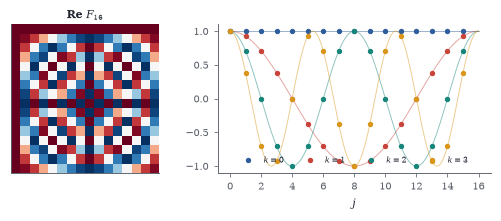

In [2]:
n = 16; jj = np.arange(n); Fm = np.exp(2j * np.pi * np.outer(jj, jj) / n)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9), gridspec_kw={"width_ratios": [1, 1.5]})
axs[0].imshow(Fm.real, cmap=CMAP, vmin=-1, vmax=1); axs[0].set_xticks([]); axs[0].set_yticks([]); axs[0].set_title(r"Re $F_{16}$", fontsize=7)
tt = np.linspace(0, n, 400)
for k, col in zip(range(4), PALETTE):
    axs[1].plot(tt, np.cos(2 * np.pi * k * tt / n), color=col, lw=0.6, alpha=0.5); axs[1].plot(jj, Fm[:, k].real, "o", color=col, ms=2.5, label=f"$k={k}$")
axs[1].set_xlabel("$j$"); axs[1].legend(fontsize=5.5, ncol=4, loc="lower center")

The FFT as sparse factors. Left: the nonzero patterns of the $\log_2 16=4$ butterfly factors and the bit-reversal permutation whose product is $F_{16}$; each factor has two nonzeros per row. Right: time to multiply by $F_n$ directly ($n^2$, grey) and by the FFT ($n\log n$, blue); for small $n$ the fixed overhead of a library call dominates both.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


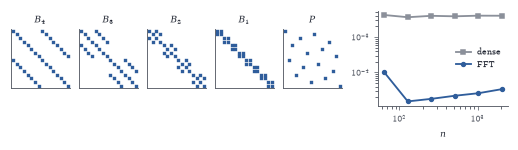

In [3]:
import time
def butterfly_factors(n):
    facs = []; m = 1
    while m < n:
        B = np.zeros((n, n), complex); w = np.exp(2j * np.pi / (2 * m))
        for start in range(0, n, 2 * m):
            for k in range(m):
                B[start + k, start + k] = 1; B[start + k, start + k + m] = w**k; B[start + k + m, start + k] = 1; B[start + k + m, start + k + m] = -w**k
        facs.append(B); m *= 2
    return facs
fac = butterfly_factors(16); bits = [int(format(i, "04b")[::-1], 2) for i in range(16)]; Pb = np.eye(16)[bits]
prod = np.eye(16)
for B in fac: prod = B @ prod
fig, axs = plt.subplots(1, 6, figsize=(W, 1.25), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1, 2.2]})
for ax, Mx, ttl in zip(axs[:5], fac[::-1] + [Pb], ["$B_4$", "$B_3$", "$B_2$", "$B_1$", "$P$"]):
    ax.spy(np.abs(Mx) > 1e-12, markersize=1.2, color=BLUE); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(ttl, fontsize=6)
ns_ = [64, 128, 256, 512, 1024, 2048]; td, tf = [], []
for n_ in ns_:
    F_ = np.exp(2j * np.pi * np.outer(np.arange(n_), np.arange(n_)) / n_); x_ = np.random.default_rng(0).normal(size=n_)
    t0 = time.perf_counter(); [F_ @ x_ for _ in range(20)]; t1 = time.perf_counter(); [np.fft.ifft(x_) for _ in range(20)]; t2 = time.perf_counter(); td.append((t1 - t0) / 20); tf.append((t2 - t1) / 20)
axs[5].loglog(ns_, td, "s-", color=GRAY, ms=2.5, label="dense"); axs[5].loglog(ns_, tf, "o-", color=BLUE, ms=2.5, label="FFT"); axs[5].set_xlabel("$n$", fontsize=6); axs[5].legend(fontsize=5); axs[5].tick_params(labelsize=5)

The convolution theorem. Left: a noisy signal (grey) and its smoothing by cyclic convolution with a Gaussian kernel, computed directly as $Cx$ (blue) and as $\bar F^{-1}(\hat c\circ\hat x)$ by FFTs (red dashed); the two agree to rounding. Right: the eigenvalues of the circulant $C$, the DFT $\hat c$ of the kernel, plotted against frequency: a low-pass filter that keeps low frequencies and suppresses high ones.

Text(0, 0.5, '$\\lambda_m=\\hat c_m$')

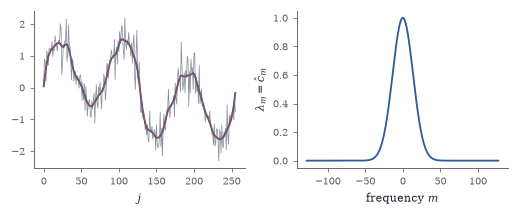

In [4]:
rng = np.random.default_rng(1); n = 256; t = np.arange(n); xs = np.sin(2 * np.pi * 3 * t / n) + 0.5 * np.sign(np.sin(2 * np.pi * t / n)) + 0.4 * rng.normal(size=n)
ker = np.exp(-0.5 * (np.minimum(t, n - t) / 3.0) ** 2); ker /= ker.sum(); Cm = np.array([np.roll(ker, k) for k in range(n)]).T
y_direct = Cm @ xs; y_fft = np.fft.ifft(np.fft.fft(ker) * np.fft.fft(xs)).real
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85))
axs[0].plot(t, xs, color=GRAY, lw=0.5); axs[0].plot(t, y_direct, color=BLUE, lw=1.2); axs[0].plot(t, y_fft, "--", color=RED, lw=0.8); axs[0].set_xlabel("$j$")
freq = np.fft.fftfreq(n) * n; order = np.argsort(freq); axs[1].plot(freq[order], np.fft.fft(ker).real[order], color=BLUE); axs[1].set_xlabel("frequency $m$"); axs[1].set_ylabel(r"$\lambda_m=\hat c_m$")

Szegő's theorem. For the symbol $a(\theta)=2-2\cos\theta+0.8\cos 3\theta$ (a trigonometric polynomial), the sorted eigenvalues of the $n\times n$ Toeplitz matrix $T_n(a)$ for $n=200$ (blue dots) follow the sorted values of $a$ at $n$ equally spaced points (red curve), the eigenvalues of the corresponding circulant. Right: histograms of the eigenvalues (blue) and of the symbol's values (red outline) agree.

Text(0.5, 0, '$\\lambda$')

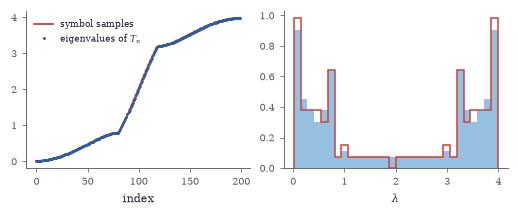

In [5]:
from scipy.linalg import toeplitz
n = 200; th = 2 * np.pi * np.arange(n) / n; a_sym = 2 - 2 * np.cos(th) + 0.8 * np.cos(3 * th)
col = np.zeros(n); col[0], col[1], col[3] = 2, -1, 0.4; Tn = toeplitz(col); evT = np.linalg.eigvalsh(Tn)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85))
axs[0].plot(np.sort(a_sym), color=RED, lw=1.2, label="symbol samples"); axs[0].plot(evT, ".", color=BLUE, ms=1.8, label="eigenvalues of $T_n$"); axs[0].set_xlabel("index"); axs[0].legend(fontsize=6)
axs[1].hist(evT, bins=30, density=True, color=SKY, alpha=0.7); axs[1].hist(a_sym, bins=30, density=True, histtype="step", color=RED); axs[1].set_xlabel(r"$\lambda$")

Circulant preconditioning for a symmetric positive definite Toeplitz system with $n=1000$, off-diagonal coefficients $t_k=-(1+|k|)^{-1.5}$ and a diagonal chosen so that the symbol is small near $\theta=0$ (condition number about $36$). Relative residual of CG without preconditioning (grey) and with Strang's circulant preconditioner (blue), applied by FFT. Inset: eigenvalues of $T$ (grey) and of $C^{-1}T$ (blue), which cluster at $1$.

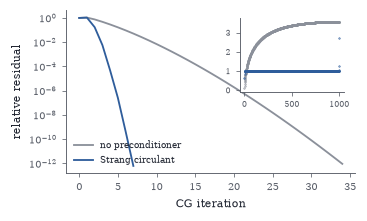

In [6]:
n = 1000; kk = np.arange(n); col = -(1.0 + kk) ** -1.5; col[0] = 2 * np.sum((1.0 + kk[1:]) ** -1.5) + 0.01; Tm = toeplitz(col); bb = np.ones(n)
cs = col.copy(); cs[n // 2 + 1:] = col[1:n - n // 2][::-1]; lamC = np.fft.fft(cs).real                   # Strang: copy central diagonals, wrap around
Minv = lambda r: np.fft.ifft(np.fft.fft(r) / lamC).real
def cg_hist(A, b, Minv, iters=200):
    x = np.zeros_like(b); r = b.copy(); z = Minv(r); p = z.copy(); h = [1.0]
    for _ in range(iters):
        Ap = A @ p; al = (r @ z) / (p @ Ap); x += al * p; rn = r - al * Ap; zn = Minv(rn); p = zn + (rn @ zn) / (r @ z) * p; r, z = rn, zn; h.append(np.linalg.norm(r) / np.linalg.norm(b))
        if h[-1] < 1e-12: break
    return h
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
ax.semilogy(cg_hist(Tm, bb, lambda r: r, 400), color=GRAY, label="no preconditioner"); ax.semilogy(cg_hist(Tm, bb, Minv), color=BLUE, label="Strang circulant"); ax.set_xlabel("CG iteration"); ax.set_ylabel("relative residual"); ax.legend(fontsize=6, loc="lower left")
Cfull = np.real(np.fft.ifft(np.fft.fft(np.eye(n), axis=0) / lamC[:, None], axis=0)); ins = ax.inset_axes([0.6, 0.5, 0.36, 0.45])
ins.plot(np.sort(np.linalg.eigvalsh(Tm)), ".", color=GRAY, ms=0.8); ins.plot(np.sort(np.linalg.eigvals(Cfull @ Tm).real), ".", color=BLUE, ms=0.8); ins.tick_params(labelsize=5)

Compression with the two-dimensional DCT. A $128\times128$ synthetic image (left) and its reconstructions keeping only the largest $5\%$ and $1\%$ of DCT coefficients (middle, right). Natural and smooth images are approximately sparse in cosine bases, which is what makes transform coding and compressed sensing (Chapter 38) work.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


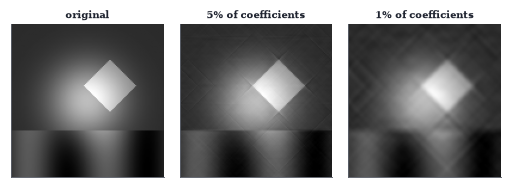

In [7]:
from scipy.fft import dctn, idctn
g = np.linspace(-1, 1, 128); GX, GY = np.meshgrid(g, g)
img = np.exp(-4 * (GX**2 + GY**2)) + 0.5 * (np.abs(GX - 0.3) + np.abs(GY + 0.2) < 0.35) + 0.3 * np.sin(6 * GX) * (GY > 0.4)
Cd = dctn(img, norm="ortho")
def keep(frac):
    thr = np.quantile(np.abs(Cd), 1 - frac); return idctn(Cd * (np.abs(Cd) >= thr), norm="ortho")
fig, axs = plt.subplots(1, 3, figsize=(W, 1.6))
for ax, Z, ttl in [(axs[0], img, "original"), (axs[1], keep(0.05), "5% of coefficients"), (axs[2], keep(0.01), "1% of coefficients")]:
    ax.imshow(Z, cmap="gray", vmin=img.min(), vmax=img.max()); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(ttl, fontsize=6.5)

In [8]:
p = np.array([1, 2, 3, 0.]); q = np.array([4, 5, 0, 0.])
print("coefficients of p*q:", np.round(np.fft.ifft(np.fft.fft(p) * np.fft.fft(q)).real, 10), "   check:", np.convolve([1, 2, 3], [4, 5]))

coefficients of p*q: [ 4. 13. 22. 15.]    check: [ 4 13 22 15]


In [9]:
def toeplitz_matvec(c_col, r_row, x):
    n = len(x); emb = np.r_[c_col, 0.0, r_row[1:][::-1]]          # first column of the 2n circulant
    return np.fft.ifft(np.fft.fft(emb) * np.fft.fft(np.r_[x, np.zeros(n)]))[:n].real
rng = np.random.default_rng(2); n = 7; cc = rng.normal(size=n); rr = np.r_[cc[0], rng.normal(size=n - 1)]; xv = rng.normal(size=n)
print("agrees with dense Toeplitz product:", np.allclose(toeplitz_matvec(cc, rr, xv), toeplitz(cc, rr) @ xv))

agrees with dense Toeplitz product: True


In [10]:
rng = np.random.default_rng(3); filt = rng.normal(size=(3, 3)); N = 16; Kpad = np.zeros((N, N)); Kpad[:3, :3] = filt
sv_fft = np.sort(np.abs(np.fft.fft2(Kpad)).ravel())[::-1]
Mconv = np.zeros((N * N, N * N))
for idx in range(N * N):
    E = np.zeros((N, N)); E.flat[idx] = 1; Mconv[:, idx] = np.real(np.fft.ifft2(np.fft.fft2(Kpad) * np.fft.fft2(E))).ravel()     # circular convolution of a basis image
print("singular values agree:", np.allclose(sv_fft, np.linalg.svd(Mconv, compute_uv=False)), "  operator norm:", round(sv_fft[0], 4))

singular values agree: True   operator norm: 7.6751
